# Non interacting picture

In [1]:
from __future__ import print_function
from pythtb import * # import TB model class
import numpy as np
import matplotlib.pyplot as plt

## Solve non-interacting BZ

In [2]:
pauli_mat =[np.array([[0,1],[1,0]]), np.array([[0,-1j],[1j,0]]), np.array([[1,0],[0,-1]])]
def solve_H(kx,ky,M):
    H = np.sin(kx)*pauli_mat[0] + np.sin(ky)*pauli_mat[1] + (M+np.cos(kx)+np.cos(ky))*pauli_mat[2]
    val,evec = np.linalg.eigh(H) #THIS LINE FUCK THIS LINE
    sorted_indices = np.argsort(val)
    sorted_val = val[sorted_indices]
    sorted_evec = evec[:, sorted_indices]
    return sorted_val,sorted_evec
    #return val,evec
def solve_BZ_noninteracting(N,k,M):
    wf_BZ = np.zeros((N,N,2,2), dtype=complex)
    eval_BZ = np.zeros((N,N,2))
    for i in range(N):
        for j in range(N):      
            (val,vec)=solve_H(k[i],k[j],M)
            #for l in range(vec.shape[1]):
            #    phase = np.angle(vec[0,l])
            #    vec = vec * np.exp(-1j*phase)
            eval_BZ[i,j] = val
            wf_BZ[i,j] = vec
    return eval_BZ, wf_BZ

## Berry Curvature over BZ

In [3]:
#recieves ni_wf[:,:,:,n] where n is the desired band
def get_BerryCurvature_1band(N,u):
    link_x=np.zeros([N,N], dtype="complex")
    link_y=np.zeros([N,N], dtype="complex")
    BC=np.zeros([N,N], dtype="complex")
    for i in range(N):
        for j in range(N):
            link_x[i,j]=(u[i-1,j,:].conj().T @ u[i,j,:])/np.abs(u[i-1,j,:].conj().T @ u[i,j,:])
            link_y[i,j]=(u[i,j-1,:].conj().T @ u[i,j,:])/np.abs(u[i,j-1,:].conj().T @ u[i,j,:])
    for i in range(N):
        for j in range(N):
            BC[i,j]=np.log(link_x[i,j]*link_y[i-1,j]/(link_x[i,j-1]*link_y[i,j]))
    return BC

In [4]:
def graph_BerryCurvature(berry_curvature):
    plt.imshow(np.imag(berry_curvature))
    plt.title('Field Strength for M')
    plt.xlabel('Nx')
    plt.ylabel('Ny')
    cbar = plt.colorbar()
    cbar.set_label('Field Strength')
    plt.show()

In [143]:
def graph_energies(evals):
    plt.imshow(evals)
    plt.title('Energy for M')
    plt.xlabel('Nx')
    plt.ylabel('Ny')
    cbar = plt.colorbar()
    cbar.set_label('Field Strength')
    plt.show()

# Interacting picture

## The Plan
following 10.1103/PhysRevB.91.075310
1) Solve the Hamiltonian for the entire $(k_x,k_y)$ grid in the non interacting picture (above)
2) Function create the Hamiltonian with interaction (direct and exchange terms) using the non interacting eigenvectors eq (6)

$D_{vv'}^{cc'}(\vec{k}\vec{k'}\vec{Q})=\frac{1}{N}V_{\vec{k}-\vec{k'}}\left(u^{\dagger}_{\vec{k}+\vec{Q}}u_{\vec{k'}+\vec{Q}}\right)_{cc'}\left(u^{\dagger}_{\vec{k'}}u_{\vec{k}}\right)_{v'v}$

$X_{vv'}^{cc'}(\vec{k}\vec{k'}\vec{Q})=\frac{1}{N}V_{\vec{Q}}\left(u^{\dagger}_{\vec{k}+\vec{Q}}u_{\vec{k}}\right)_{cv}\left(u^{\dagger}_{\vec{k'}}u_{\vec{k'}+\vec{Q}}\right)_{v'c'}$

Use the non interacting eigenvalues as well as D and X in the following equation (5)

$
\begin{equation}
\langle v, c, \vec{k}, \vec{Q} | H | v', c', \vec{k'}, \vec{Q'} \rangle = \delta_{vv'} \delta_{cc'} \delta_{kk'} \left( \epsilon_{(\vec{k} + \vec{Q}) c} - \epsilon_{\vec{k} v}\right) - (D - X)^{c c'}_{v v'} (\vec{k}, \vec{k'}, \vec{Q}) 
\end{equation}
$

3) loop over every Q leading to eigenvalues $\epsilon_Q$ and eigenvectors $F(Q,P)$
4) graph e_q and integrated F

### Step 1 
use the previous functions to get 2D eigenfunc matrix of the entire BZ, run non pythTB block for entire BZ.<br>
eigenvalues [k_x][k_y][n]. conduction: n = 0, valance: n = 1.<br>
eigenvectors [kx][ky][j][n] x: j=0, y: j=1

In [159]:
#wf_noninteracting, wf_ni_np, ni_evals = get_BZ_eigenfunc(model, square_step) 
Nk=10
M=-1.1
klist = np.linspace(-np.pi,np.pi,Nk)
ni_evals, ni_wf = solve_BZ_noninteracting(Nk,klist,M)
kx_max, ky_max = Nk,Nk
#using klist and Qlist with the same jumps between values so everything lines up nicely. 
#its good to work like this so i dont have to think about units all the time, klist and Qlist are in radians while the rest of the time k and Q are indices which match the lists

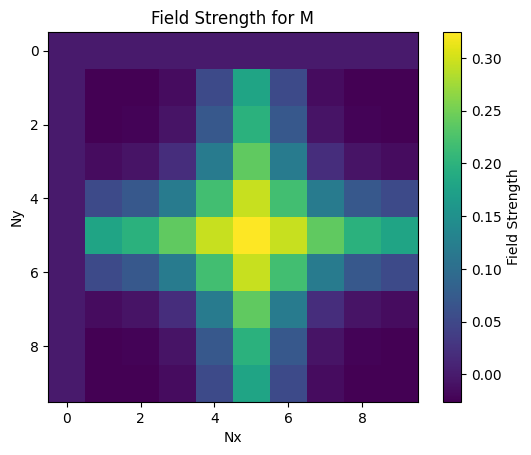

In [160]:
#Use berry curvature to make sure eigvecs are correct
BC = get_BerryCurvature_1band(Nk,ni_wf[:,:,:,0])
graph_BerryCurvature(BC)

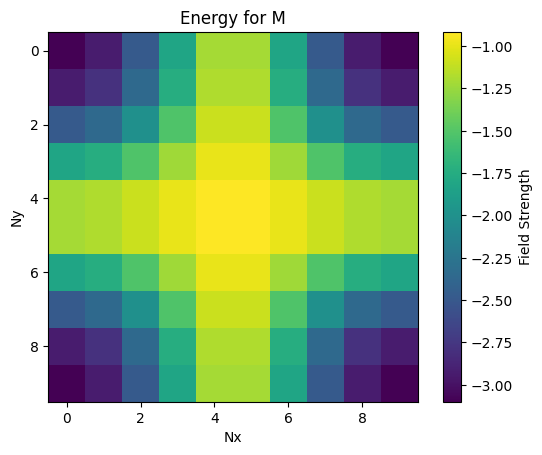

In [161]:
graph_energies(ni_evals[:,:,0])

### Step 2
Define func get_H(Q,wf_array) which returns the 4D H tensor for each Q depending on the wavefunctions of the non interacting problem.
notes: currently assumes a 2 band system, therfore no consideration for difference between different bands c=c' v=v'.

In [184]:
U=16
def get_H(Qx_indx,Qy_indx,wf_ni, ni_evals,half_dQ):
    H = np.zeros((Qx_max,kx_max,Qy_max,ky_max), dtype = complex) #H(k,k')
    for kx in range(kx_max):
        for ky in range(ky_max):
            for kx_tag in range(kx_max):
                for ky_tag in range(ky_max):
                    #precalculate the whole modulu buisness
                    kx_Qx = (kx+Qx_indx)%kx_max  
                    kx_Qx_tag = (kx_tag+Qx_indx)%kx_max
                    ky_Qy = (ky+Qy_indx)%ky_max
                    ky_Qy_tag = (ky_tag+Qy_indx)%ky_max
                    if kx==kx_tag and ky==ky_tag:
                        e = ni_evals[kx_Qx][ky_Qy][0]- ni_evals[kx][ky][1]
                    else:
                        e = 0
                    #units for the coulomb interaction are not taken into account! this is simply porpotions.
                    V_d = 1/(pow(Nk,2)*(np.sqrt((pow(klist[kx-kx_tag],2) + pow(klist[ky-ky_tag],2))))+1e-3) #mine e-3 outside of n^2 Carolinas inside
                    V_x = 1/(pow(Nk,2)*(np.sqrt(pow(Qlist[Qx_indx]+half_dQ,2)+pow(Qlist[Qy_indx]+half_dQ,2)))+1e-3)
                    D = U*V_d*np.vdot(wf_ni[kx_Qx,ky_Qy,:,0],wf_ni[kx_Qx_tag,ky_Qy_tag,:,0])*np.vdot(wf_ni[kx_tag,ky_tag,:,1],wf_ni[kx,ky,:,1]) #N=1?
                    X = U*V_x*np.vdot(wf_ni[kx_Qx,ky_Qy,:,0],wf_ni[kx,ky,:,1])*np.vdot(wf_ni[kx_tag,ky_tag,:,1],wf_ni[kx_Qx_tag,ky_Qy_tag,:,0]) #vdot already takes conj
                    H[kx,ky,kx_tag,ky_tag] = e - (D-X)
    return H

### Step 3
Loop over every Q from $-2\pi$ to $2\pi$ using the same difference between k's (so if k is 20x20 Q is 40x40). Flatten H to a 2D matrix. Solve the eigensystem of the 2D matrix, save the eigenvalues of Q.

In [132]:
import time

In [185]:
start_time = time.time()
NQ =2*Nk-1 #-1
dQ = (4*np.pi)/(NQ-1)
Qx_max,Qy_max = NQ,NQ
eQ_matrix = np.zeros((Qx_max,Qy_max,kx_max*ky_max))
integrated_f_matrix = np.zeros((Qx_max,Qy_max,kx_max*ky_max),dtype=np.complex128)
Qlist = np.linspace(-2*np.pi,2*np.pi,NQ)
for i in range(Qx_max):
    for j in range(Qy_max):
        H_Q = get_H(i,j,ni_wf,ni_evals,dQ/2)
        H_Q2D = Flatten4D(H_Q)
        e_Q, f_Q = np.linalg.eigh(H_Q2D)
        # Sort the eigenvalues and reorder eigenvectors accordingly
        sorted_indices = np.argsort(e_Q)
        sorted_e_Q = e_Q[sorted_indices]
        sorted_f_Q = f_Q[:, sorted_indices]
        #if np.all(abs(e_Q.imag) < 1e-10):
        sorted_e_Q = np.real(sorted_e_Q)
        #else:
         #   print(f"Complex eigenvalue in interacting picture at Qx = {Qx} Qy = {Qy}")
        eQ_matrix[i][j]= sorted_e_Q 
        integrated_f_matrix[i][j] = np.sum(sorted_f_Q, axis=0) 
end_time = time.time()
print(end_time - start_time)

47.976600646972656


note about flattening, we go from $H_{ijkl} -> H_{i'j'}$, I want the first index to represent k and the second to represent k'. in order to do that I flattened it in such a way that $i' = i*N_{ky} + j$ and $j' = k*N_{ky} +l$ I feel like this makes the most sense. To unwind simply take floor or modulu of the index by N.

In [170]:
def Flatten4D(array4D):
    imax,jmax,kmax,lmax = kx_max,ky_max,kx_max,ky_max #this can be made more generic but im trying to minmax efficiency a little bit
    # Flatten the 4D array to a 2D array using explicit index mapping
    array2D = np.empty((imax * jmax, kmax * lmax), dtype=complex)
    
    for i in range(imax):
        for j in range(jmax):
            for k in range(kmax):
                for l in range(lmax):
                    # Map 4D indices to 2D indices
                    row = i * jmax + j
                    col = k * lmax + l
                    array2D[row, col] = array4D[i, j, k, l]
    return array2D

# Verify index mapping
#for i in range(imax):
#    for j in range(jmax):
#        for k in range(kmax):
#            for l in range(lmax):
#                if array2D[i * jmax + j][k * lmax + l] != array4D[i][j][k][l]:
#                    print("Error in mapping")

In [171]:
#unused rn, Unflatten
def UnFlatten2D(array2D):
    # Reverse the flattening process
    for row in range(imax * jmax):
        for col in range(kmax * lmax):
            # Convert 2D indices (row, col) back to 4D indices (i, j, k, l)
            i = row // jmax
            j = row % jmax
            k = col // lmax
            l = col % lmax
            
            # Assign the value from 2D array to 4D array
            array4D[i, j, k, l] = array2D[row, col]
    return array4D

### Step 4
graphs

In [172]:
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
from matplotlib.ticker import FuncFormatter

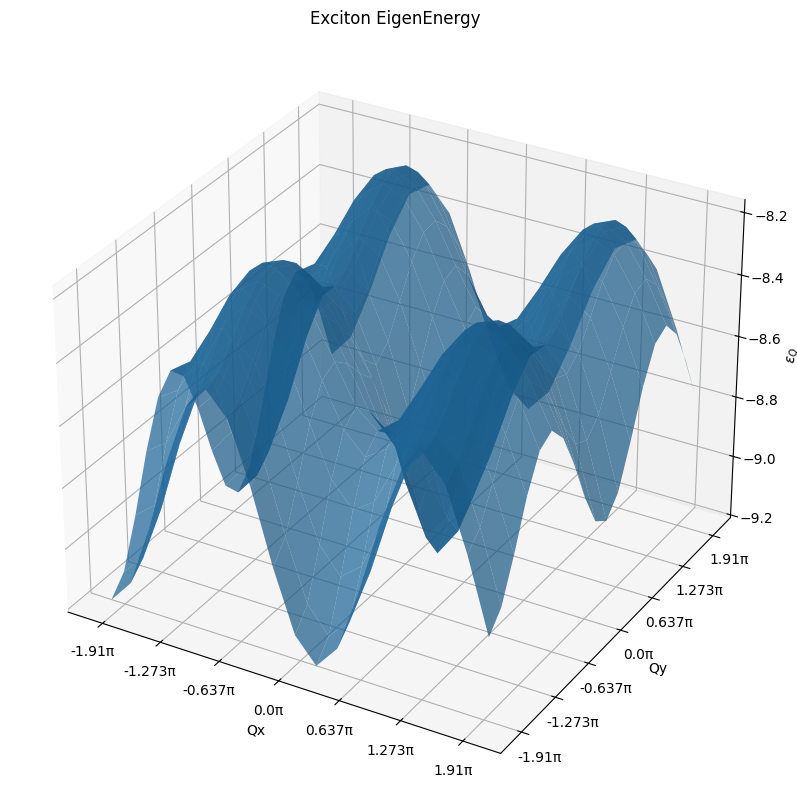

In [186]:
def pi_formatter(value, tick_number):#just to be cute
    return f"{np.round(value/np.pi,3)}π"
Qx_mesh, Qy_mesh = np.meshgrid(Qlist,Qlist)
fig = plt.figure(figsize=(10, 10))
ax = fig.add_subplot(111, projection='3d')
for i in range(1): #choose bands
    eQ_sheet = eQ_matrix[:,:,i]
    ax.plot_surface(Qx_mesh, Qy_mesh, eQ_sheet, alpha=0.7, label=f"band {i}")
ax.xaxis.set_major_formatter(FuncFormatter(pi_formatter))
ax.yaxis.set_major_formatter(FuncFormatter(pi_formatter))
ax.set_xlabel('Qx')
ax.set_ylabel('Qy')
ax.set_zlabel(r'$\epsilon_Q$')
plt.title("Exciton EigenEnergy")
plt.savefig('EigenEnergies3D_eigH.png')
plt.show()

#fig = plt.figure(figsize=(10, 10))
#ax = fig.add_subplot(111, projection='3d')
#for i in range(1):
#    sigma_f_sheet = np.abs(integrated_f_matrix[:,:,i])
#    ax.plot_surface(Qx_mesh, Qy_mesh, sigma_f_sheet, alpha=0.7, label=f"band {i}")
#ax.set_zlabel('Integrated F(p,Q)')
#plt.title("YURP")
#plt.show()

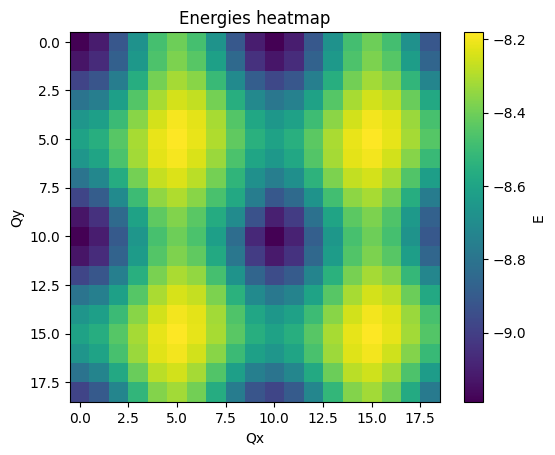

In [187]:
plt.imshow(eQ_matrix[:,:,0])
plt.title('Energies heatmap')
plt.xlabel('Qx')
plt.ylabel('Qy')
cbar = plt.colorbar()
cbar.set_label('E')
plt.savefig(f'2D_Eigenenergies_NQ={NQ}.png')
plt.show()

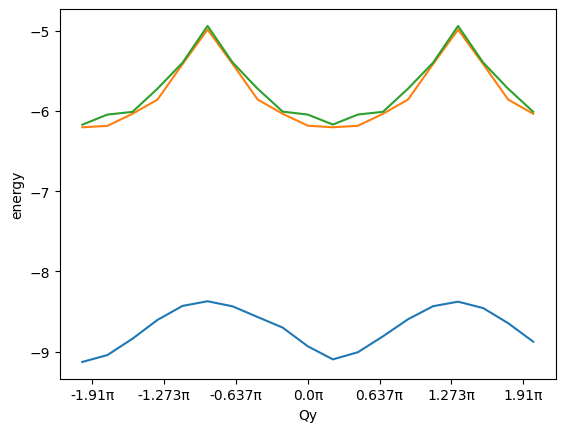

In [190]:
rows, cols, n = eQ_matrix.shape
center_row = rows // 2
center_plus1 = rows - center_row
#band = np.zeros(3*(center_plus1))
count = 3
for i in range(count):
   # line1 = [eQ_matrix[center_row + j-1, center_row + j-1,i] for j in range(center_plus1)]
   # line2 = [eQ_matrix[rows-1, rows - j-2,i] for j in range(center_plus1-1)] #-2 and -1 to avoid using the same point twice
   # line3 = [eQ_matrix[rows - j-1, center_row-1,i] for j in range(center_plus1-1)]
   # band = line1 + line2 + line3
    band = [eQ_matrix[center_row,j,i] for j in range(cols)]
    plt.plot(Qlist,band)
#xticks_positions = [
#    0,                      # Start of the first line
#    len(line1)-1,         # End of the first line
#    len(line1) + len(line2)-2,  # End of the second line
#    len(band)-1          # End of the third line
#]
#xtick_labels = [r"$\Gamma$", r"M", r"X", r"$\Gamma$"]
# Set custom xticks
#plt.xticks(ticks=xticks_positions, labels=xtick_labels)
plt.xlabel("Qy")
ax = plt.gca()
ax.xaxis.set_major_formatter(FuncFormatter(pi_formatter))
plt.ylabel("energy")
#plt.legend()
plt.savefig(f'EigenEnergies_{count}_1D_Qx=pi.png')
plt.show()

TODO:
more Nk to smooth

constant interaction

once we are confident abt the calculations, new models.

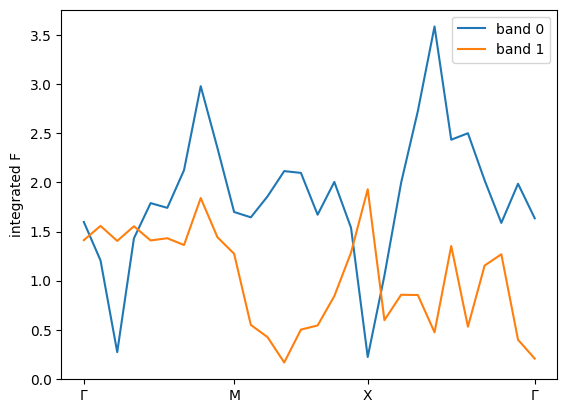

In [25]:
integrated_f_matrix = np.abs(integrated_f_matrix)
rows, cols, n = integrated_f_matrix.shape
center_row = rows // 2
center_col = cols // 2
for i in range(2):
    line1 = [integrated_f_matrix[center_row + j-1, center_row + j-1,i] for j in range(center_plus1)]
    line2 = [integrated_f_matrix[rows-1, rows - j-2,i] for j in range(center_plus1-1)]
    line3 = [integrated_f_matrix[rows - j-2, center_row-1,i] for j in range(center_plus1-1)]
    band = line1 + line2 + line3
    plt.plot(band, label = f"band {i}")
xticks_positions = [
    0,                      # Start of the first line
    len(line1)-1,         # End of the first line
    len(line1) + len(line2)-2,  # End of the second line
    len(band)-1          # End of the third line
]
xtick_labels = [r"$\Gamma$", r"M", r"X", r"$\Gamma$"]
# Set custom xticks
plt.xticks(ticks=xticks_positions, labels=xtick_labels)
plt.ylabel("integrated F")
plt.legend()
plt.show()